# Maxi: medición, estadística y análisis

Pruebas de `src/measurement.py` y `src/analysis.py` (ítems 2 a 5 de `docs/task_split.md`).

Como todavía no hay ansatz optimizado, se usan tres estados de prueba de 8 qubits sobre el hamiltoniano real de H₄ a 2,4 Å:

- **HF**: el determinante de Hartree-Fock (las `X` en los qubits ocupados).
- **mix**: HF más rotaciones `ry` al azar y una cadena de `cx`. Es un estado genérico, que **no** es autoestado ni conserva N.
- **FCI**: el estado fundamental exacto, cargado con `initialize`. **Solo para probar**: la consigna no deja usarlo como resultado, pero sirve porque sabemos qué tiene que dar (N = 4, S² = 0, Var(H) = 0).

Los valores "exactos" se calculan con `Statevector` únicamente para comparar.

In [1]:
import sys, time
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

from hamiltonian import build_problem, DISTANCES
from measurement import (measure_energy, measure_expectation, validate_sigma,
                         compare_allocations, shots_for_sigma, measure_reliability)
from analysis import make_record, report, results_table, beats_ccsd

pd.set_option("display.precision", 5)
%matplotlib inline

In [2]:
p = build_problem(2.4)
H = p["hamiltonian"]
print(f"{len(H)} términos de Pauli, {len(H.group_commuting(qubit_wise=True))} grupos que conmutan qubit a qubit")

def hf_circuit(problem):
    qc = QuantumCircuit(problem["n_qubits"])
    for q, bit in enumerate(problem["hf_bitstring"][::-1]):   # qubit 0 = carácter de la derecha
        if bit == "1":
            qc.x(q)
    return qc

qc_hf = hf_circuit(p)

qc_mix = qc_hf.copy()
rng = np.random.default_rng(1)
for q in range(8):
    qc_mix.ry(rng.uniform(-0.4, 0.4), q)
for q in range(7):
    qc_mix.cx(q, q + 1)

# estado fundamental exacto en el sector N = 4, S² = 0 (solo para probar)
Hm, Nm, S2m = (p[k].to_matrix() for k in ("hamiltonian", "number_op", "s2_op"))
I = np.eye(Hm.shape[0])
_, vecs = np.linalg.eigh(Hm + 10 * (Nm - 4 * I) @ (Nm - 4 * I) + 10 * S2m)
qc_fci = QuantumCircuit(8)
qc_fci.initialize(vecs[:, 0], range(8))

states = {"HF": qc_hf, "mix": qc_mix, "FCI": qc_fci}

185 términos de Pauli, 46 grupos que conmutan qubit a qubit


## 1. `measure_energy` contra el valor exacto

Con 20 000 shots, la diferencia con el valor exacto tiene que ser del orden de σ (|z| ≲ 2).

In [3]:
rows = []
for name, qc in states.items():
    exact = Statevector(qc).expectation_value(H).real
    r = measure_energy(qc, None, H, 20_000, seed=1)
    rows.append({"estado": name, "E exacta": exact, "E medida": r["energy"],
                 "σ (mHa)": 1e3 * r["sigma"], "z": (r["energy"] - exact) / r["sigma"], "shots": r["shots"]})
pd.DataFrame(rows)

,estado,E exacta,E medida,σ (mHa),z,shots
0,HF,-1.43646,-1.42564,15.61661,0.69280,20000
1,mix,-0.74554,-0.75693,16.37945,-0.69551,20000
2,FCI,-1.87465,-1.88183,14.93170,-0.48063,20000


## 2. Validación de σ (ítem 2)

Se repite la medición 30 veces con semillas distintas. Si σ está bien calculada, la desviación estándar de las 30 energías tiene que coincidir con la σ reportada. Con 30 muestras, esa desviación tiene un error relativo de $1/\sqrt{2\cdot 29} \approx 13\,\%$, así que un cociente entre 0,75 y 1,25 está bien.

desviación de las 30 energías: 19.11 ± 2.51 mHa
σ reportada (promedio):         16.41 mHa
cociente:                       1.16
media - exacta:                 +3.15 mHa (error de la media: 3.49 mHa)
fracción dentro de ±σ: 73% (se espera ~68 %)


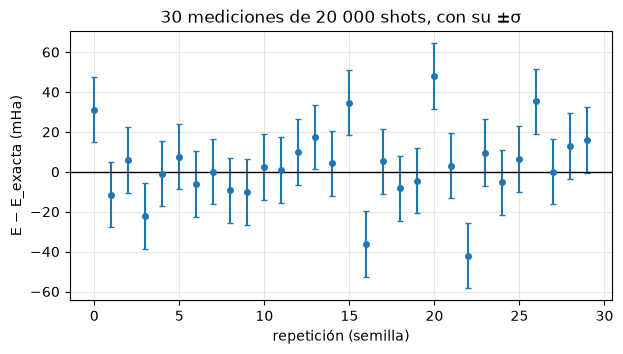

In [4]:
exact_mix = Statevector(qc_mix).expectation_value(H).real
v = validate_sigma(qc_mix, None, H, 20_000, n_repeats=30)
print(f"desviación de las 30 energías: {1e3 * v['std_energies']:.2f} ± {1e3 * v['std_energies_error']:.2f} mHa")
print(f"σ reportada (promedio):         {1e3 * v['mean_sigma']:.2f} mHa")
print(f"cociente:                       {v['ratio']:.2f}")
print(f"media - exacta:                 {1e3 * (v['mean_energy'] - exact_mix):+.2f} mHa "
      f"(error de la media: {1e3 * v['std_energies'] / np.sqrt(30):.2f} mHa)")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(range(30), 1e3 * (v["energies"] - exact_mix), yerr=1e3 * v["sigmas"], fmt="o", ms=4, capsize=2)
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("repetición (semilla)")
ax.set_ylabel("E − E_exacta (mHa)")
ax.set_title("30 mediciones de 20 000 shots, con su ±σ")
ax.grid(alpha=0.3)
inside = np.mean(np.abs(v["energies"] - exact_mix) < v["sigmas"])
print(f"fracción dentro de ±σ: {inside:.0%} (se espera ~68 %)")

## 3. Reparto de shots (ítem 3)

- **uniform**: los mismos shots para cada grupo.
- **weighted**: proporcional a $\sum_k |c_k|$ del grupo (el que usamos por defecto).
- **adaptive**: una corrida piloto con el 10 % de los shots estima la dispersión $\sigma_g$ de cada grupo, y el resto se reparte proporcional a $\sigma_g$ (reparto de Neyman, el que minimiza $\sum_g \sigma_g^2/N_g$).

La última columna es cuántos shots harían falta para $\sigma < 1$ mHa, usando $\sigma \propto 1/\sqrt{N}$.

In [5]:
t0 = time.time()
alloc = pd.DataFrame(compare_allocations(qc_mix, None, H, 20_000, n_repeats=30))
alloc["mean_sigma"] *= 1e3
alloc["std_energies"] *= 1e3
alloc = alloc.rename(columns={"mean_sigma": "σ reportada (mHa)", "std_energies": "desv. real (mHa)",
                              "ratio": "cociente", "shots_for_target": "shots para σ<1 mHa"})
print(f"{time.time() - t0:.0f} s")
alloc

44 s


,allocation,shots,mean_energy,σ reportada (mHa),desv. real (mHa),cociente,shots para σ<1 mHa
0,uniform,20000,-0.74611,16.90364,18.99188,1.12354,5714665
1,weighted,20000,-0.74239,16.40850,19.10618,1.16441,5384778
2,adaptive,20000,-0.74672,14.37830,16.59119,1.15390,4134709


Comprobación de $\sigma \propto 1/\sqrt{N}$: σ medida para distintos presupuestos, contra la predicción a partir de 20 000 shots.

shots para σ < 1 mHa: 5384531


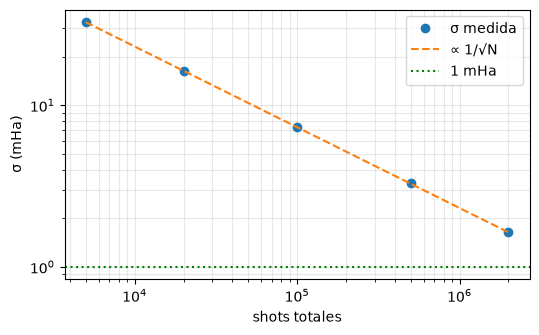

In [6]:
budgets = [5_000, 20_000, 100_000, 500_000, 2_000_000]
sig = [measure_energy(qc_mix, None, H, n, seed=7)["sigma"] for n in budgets]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(budgets, 1e3 * np.array(sig), "o", label="σ medida")
ax.loglog(budgets, 1e3 * sig[1] * np.sqrt(budgets[1] / np.array(budgets)), "--", label="∝ 1/√N")
ax.axhline(1, color="green", ls=":", label="1 mHa")
ax.set_xlabel("shots totales")
ax.set_ylabel("σ (mHa)")
ax.legend()
ax.grid(alpha=0.3, which="both")
print("shots para σ < 1 mHa:", shots_for_sigma(sig[-1], budgets[-1]))

## 4. Indicadores de confiabilidad (ítem 4)

Medidos con el mismo código y con shots: $\langle N\rangle$ (tiene que dar 4), $\langle S^2\rangle$ (0 para el fundamental) y $\mathrm{Var}(H) = \langle H^2\rangle - \langle H\rangle^2$, que es cero solo si el estado es un autoestado. El estado FCI tiene que pasar las tres pruebas; HF tiene N y S² correctos pero varianza positiva, y "mix" falla en las tres.

In [7]:
rows = []
for name, qc in states.items():
    sv = Statevector(qc)
    r = measure_reliability(qc, None, H, p["number_op"], p["s2_op"], 50_000, seed=3)
    rows.append({
        "estado": name,
        "N": f"{r['N']:.3f} ± {r['N_sigma']:.3f}", "N exacto": sv.expectation_value(p["number_op"]).real,
        "S²": f"{r['S2']:.3f} ± {r['S2_sigma']:.3f}", "S² exacto": sv.expectation_value(p["s2_op"]).real,
        "Var(H)": f"{r['variance']:.4f} ± {r['variance_sigma']:.4f}",
        "Var(H) exacta": (sv.expectation_value(H @ H) - sv.expectation_value(H) ** 2).real,
    })
pd.DataFrame(rows)

,estado,N,N exacto,S²,S² exacto,Var(H),Var(H) exacta
0,HF,4.000 ± 0.000,4.00000,-0.027 ± 0.028,0.00000e+00,0.1654 ± 0.0174,0.14795
1,mix,2.362 ± 0.005,2.36309,0.136 ± 0.029,1.50981e-01,0.0750 ± 0.0175,0.08947
2,FCI,4.000 ± 0.000,4.00000,0.077 ± 0.033,-1.80411e-16,0.0429 ± 0.0295,0.00000


## 5. Análisis con datos inventados (ítem 5)

Todavía no hay resultados de VQE, así que se arma una curva **falsa** para probar `analysis.py`: en cada distancia, $E = E_\text{FCI} + 0{,}3$ mHa $+$ ruido, con $\sigma = 0{,}8$ mHa (lo que daría ~8 M shots). Cuando Fede tenga `optimize`, se reemplaza `fake_measurement` por `measure_energy` del circuito optimizado y el resto queda igual.

build_problem para 15 distancias: 10 s


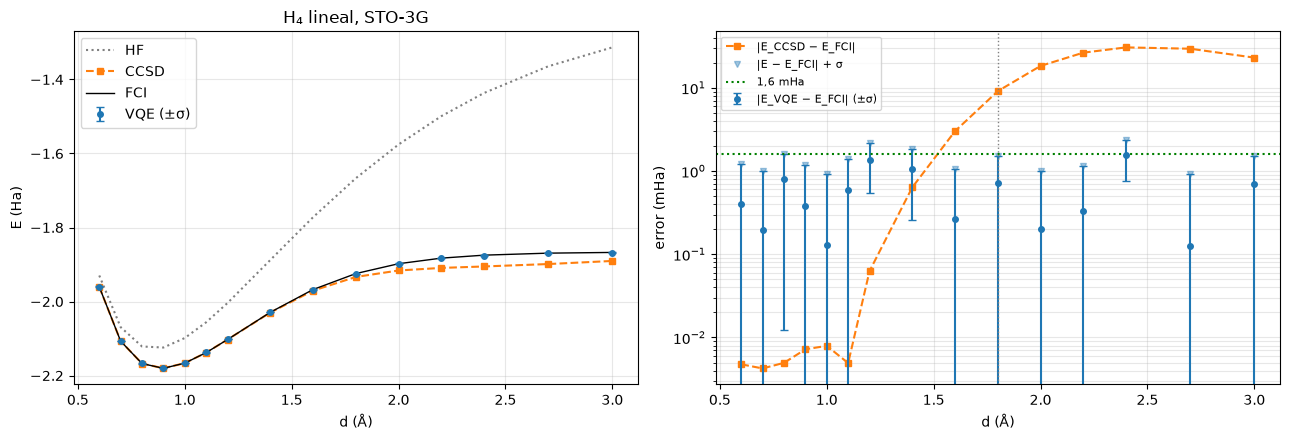

In [8]:
t0 = time.time()
problems = [build_problem(d) for d in DISTANCES]
print(f"build_problem para {len(DISTANCES)} distancias: {time.time() - t0:.0f} s")

rng = np.random.default_rng(0)
def fake_measurement(problem, sigma=0.8e-3, bias=0.3e-3):
    return {"energy": problem["e_fci"] + bias + sigma * rng.standard_normal(), "sigma": sigma, "shots": 8_000_000}

records = [make_record("fake", prob, theta=None, measurement=fake_measurement(prob), cz=0) for prob in problems]
out = report(records)

### Tabla para la entrega

`le gana a CCSD` solo se evalúa para $d \ge 1{,}8$ Å: es el criterio $|E-E_\text{FCI}|+\sigma < |E_\text{CCSD}-E_\text{FCI}|$ de la consigna.

In [9]:
out["table"]

,d (Å),E (Ha),σ (mHa),shots,cz,E_CCSD (Ha),E_FCI (Ha),|E-E_FCI| (mHa),|E_CCSD-E_FCI| (mHa),le gana a CCSD,precisión química
0,0.6,-1.95979,0.8,8000000,0,-1.96019,-1.96019,0.40058,0.00476,None,True
1,0.7,-2.10680,0.8,8000000,0,-2.10699,-2.10700,0.19432,0.00424,None,True
2,0.8,-2.16675,0.8,8000000,0,-2.16756,-2.16756,0.81234,0.00496,None,True
3,0.9,-2.17993,0.8,8000000,0,-2.18031,-2.18032,0.38392,0.00720,None,True
4,1.0,-2.16652,0.8,8000000,0,-2.16638,-2.16639,0.12854,0.00793,None,True
5,1.1,-2.13738,0.8,8000000,0,-2.13798,-2.13797,0.58928,0.00492,None,True
6,1.2,-2.10127,0.8,8000000,0,-2.10267,-2.10261,1.34320,0.06266,None,True
7,1.4,-2.02801,0.8,8000000,0,-2.02971,-2.02907,1.05766,0.63647,None,True
8,1.6,-1.96782,0.8,8000000,0,-1.97057,-1.96756,0.26299,3.01191,None,True
9,1.8,-1.92514,0.8,8000000,0,-1.93354,-1.92443,0.71234,9.10764,True,True


### Curva y errores

Izquierda: la curva con barras de error contra HF, CCSD y FCI. Derecha: el error respecto de FCI en escala logarítmica; CCSD (naranja) se dispara desde ~1,4 Å y la línea verde es la precisión química (1,6 mHa).

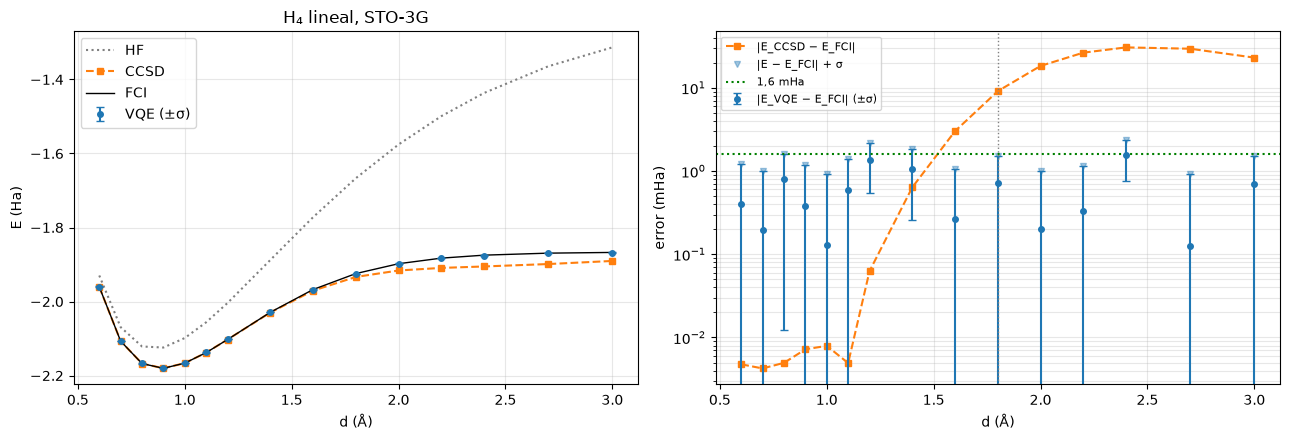

In [10]:
out["figure"]

### $R_e$ y $D_e$

$R_e$ sale de un spline cúbico por los puntos, con el error estimado remuestreando las energías dentro de su σ. $D_e = E(3{,}0\,\text{Å}) - E(R_e)$. Para comparar: el mínimo de FCI en una grilla densa está en 0,8882 Å.

In [11]:
out["summary"]

,método,R_e (Å),σ R_e (Å),E(R_e) (Ha),D_e (Ha),σ D_e (mHa)
0,VQE,0.89117,0.0037,-2.18004,0.31205,1.12146
1,CCSD,0.88842,0.0000,-2.18049,0.29019,0.00000
2,FCI,0.88843,0.0000,-2.18050,0.31321,0.00000


In [12]:
check = out["beats_ccsd"]
print("le gana a CCSD en todos los puntos con d ≥ 1,8 Å:", check["all_ok"])
print("precisión química en esa zona:", check["all_chemical_accuracy"])
pd.DataFrame(check["points"])

le gana a CCSD en todos los puntos con d ≥ 1,8 Å: True
precisión química en esa zona: True


,d,lhs_mHa,rhs_mHa,ok,chemical_accuracy
0,1.8,1.51234,9.10764,True,True
1,2.0,0.99862,18.30545,True,True
2,2.2,1.13306,26.40768,True,True
3,2.4,2.36002,30.56001,True,True
4,2.7,0.92497,29.44582,True,True
5,3.0,1.49673,23.01300,True,True
